# Projet HMM Crypto — Notebook CRISP-DM (phases 1 à 3)

**Sujet :** modélisation et prédiction des régimes de marché des cryptomonnaies par modèles cachés de Markov (**HMM**).  
**Livrable actuel :** Business Understanding, Data Understanding, Data Preparation. **Aucun HMM ni backtesting** dans ce notebook.  
**Actifs :** BTC-USD et ETH-USD. **Période :** 01/01/2018 au 18/11/2026 inclus. **Fréquence :** journalière.  
**Source :** Yahoo Finance via `yfinance`, déjà collectée dans `data/raw/`.

> **Conventions :** les CSV bruts ne sont jamais modifiés. Nous conservons les mouvements extrêmes du marché ; les lignes techniquement invalides sont **isolées et journalisées**, pas supprimées silencieusement. Les conclusions statistiques sont exploratoires, et les résultats affichés proviennent uniquement des CSV réellement lus lors de l'exécution.

**Mode d'emploi :** lancer les cellules dans l'ordre avec le noyau `C:\HMM_Crypto\.venv\Scripts\python.exe`. Si nécessaire : `python -m pip install ipykernel scipy statsmodels scikit-learn`.

## Phase 1 — Business Understanding (compréhension métier)

### Contexte
Les marchés des cryptomonnaies se caractérisent par des périodes de croissance, de baisse et de forte turbulence. Les seuls prix observés ne donnent pas directement l'état sous-jacent du marché.

### Problématique métier
**Comment identifier et caractériser les régimes cachés (Bullish, Bearish, Panique) de Bitcoin et d'Ethereum afin d'estimer leurs transitions et, ultérieurement, de tester leur utilité pour la décision d'investissement ?**

### Objectifs métier
- Distinguer les phases de marché à partir de signaux financiers observables.
- Étudier les probabilités de transition entre les états.
- Évaluer ultérieurement si l'information sur les régimes améliore la gestion du risque et une stratégie de trading, par rapport à une référence *Buy and Hold*.

### Objectifs analytiques à terme
1. Collecter et documenter les historiques OHLCV (Open, High, Low, Close, Volume).
2. Vérifier la qualité des données ; construire les rendements et indicateurs financiers.
3. Comparer des modèles HMM et le nombre d'états (AIC/BIC, validation chronologique).
4. Évaluer la stabilité des régimes et éviter toute fuite d'informations futures lors du backtesting.

### Critères de succès de **ce** livrable (phases 1 à 3)
- Sources, unités, période et fréquence explicitées.
- Anomalies de dates, doublons, valeurs non finies, incohérences OHLCV et interruptions détectées et quantifiées.
- Données préparées conservant les krachs réels ; opérations reproductibles et auditées.
- Analyses descriptives visuelles et statistiques accompagnées d'interprétations **conditionnelles aux résultats**.
- Pas d'entraînement HMM ou de performance de trading revendiquée ici.

**Périmètre et limite :** deux actifs, observations journalières en USD, source unique Yahoo Finance. Les prix, volumes et événements extrêmes peuvent différer d'autres places de marché : une vérification croisée sera souhaitable par la suite.

## Phase 2 — Data Understanding (compréhension des données)

**Objectif :** explorer et comprendre les sources avant toute décision de nettoyage définitif. Nous inspectons les données originales, les caractéristiques financières, les distributions et les dépendances temporelles.

**Convention méthodologique :** pour analyser les rendements en phase 2, une **vue temporaire en mémoire** est constituée à partir des observations techniquement admissibles : date unique, cours strictement positifs, volumes non négatifs, bougie cohérente et valeurs finies. Elle sert *uniquement* à l'analyse exploratoire, sans écraser les CSV d'origine ni enregistrer les fichiers propres. Les cas écartés de cette vue restent documentés dans le diagnostic ; leur traitement définitif intervient **uniquement en phase 3**. Les rendements ne sont calculés que lorsque deux jours consécutifs sont présents.

Cette distinction évite d'interpréter des données manifestement impossibles tout en conservant une présentation linéaire des phases CRISP-DM.

### Cellule 1 — Configuration et bibliothèques
**Question :** les fichiers et les bibliothèques sont-ils accessibles ?

In [17]:
from pathlib import Path
from IPython.display import display
import os
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

# Recherche de la racine lorsque le notebook est lancé depuis le projet ou notebooks/.
CANDIDATS = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
RACINE = next((p for p in CANDIDATS if (p / "data" / "raw").is_dir()), None)
if RACINE is None:
    raise FileNotFoundError("Dossier data/raw introuvable : ouvrir C:\\HMM_Crypto dans VS Code.")

RAW_DIR = RACINE / "data" / "raw"
PROCESSED_DIR = RACINE / "data" / "processed"
REPORT_DIR = RACINE / "outputs" / "qualite"
FIG_DIR = RACINE / "outputs" / "exploration"

DEBUT = pd.Timestamp("2018-01-01")
FIN = pd.Timestamp("2026-11-18")
DATES_ATTENDUES = pd.date_range(DEBUT, FIN, freq="D")
ACTIFS = {"BTC": "BTC-USD_1d.csv", "ETH": "ETH-USD_1d.csv"}
REQUISES = ["Date", "Open", "High", "Low", "Close", "Volume"]
PRIX = ["Open", "High", "Low", "Close"]

print("Projet :", RACINE)
print("Période :", DEBUT.date(), "→", FIN.date())
print("Jours calendaires attendus :", len(DATES_ATTENDUES))
print("Actifs :", ", ".join(ACTIFS))
REPORT_DIR.mkdir(parents=True, exist_ok=True)


Projet : C:\HMM_Crypto
Période : 2018-01-01 → 2026-11-18
Jours calendaires attendus : 3244
Actifs : BTC, ETH


### Cellule 2 — Chargement brut et aperçu
**Pourquoi ?** Vérifier que chaque date correspond à une ligne de données et que les colonnes OHLCV attendues sont présentes. `Adj Close` est conservée dans la source, mais notre table de travail utilise `Close`.

**Interprétation attendue :** comparer le nombre de lignes à la couverture journalière demandée et examiner les formats de date, prix et volume.

In [18]:
bruts = {}
for actif, nom_fichier in ACTIFS.items():
    chemin = RAW_DIR / nom_fichier
    if not chemin.exists():
        raise FileNotFoundError(f"Fichier absent : {chemin}. Exécuter la collecte d'abord.")
    df = pd.read_csv(chemin)  # AUCUNE modification de la source
    manquantes = [col for col in REQUISES if col not in df.columns]
    if manquantes:
        raise ValueError(f"{actif} : colonnes obligatoires absentes : {manquantes}")
    bruts[actif] = df
    print(f"\n{actif} : {df.shape[0]:,} lignes, {df.shape[1]} colonnes")
    print("Colonnes :", list(df.columns))
    display(df.head(3))
    display(df.dtypes.rename("Type initial").to_frame())


BTC : 3,244 lignes, 7 colonnes
Colonnes : ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


,Date,Adj Close,Close,High,Low,Open,Volume
0,2018-01-01,"13,657.20020","13,657.20020","14,112.20020","13,154.70020","14,112.20020",10291200000
1,2018-01-02,"14,982.09961","14,982.09961","15,444.59961","13,163.59961","13,625.00000",16846600192
2,2018-01-03,"15,201.00000","15,201.00000","15,572.79980","14,844.50000","14,978.20020",16871900160


,Type initial
Date,object
Adj Close,float64
Close,float64
High,float64
Low,float64
Open,float64
Volume,int64



ETH : 3,244 lignes, 7 colonnes
Colonnes : ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


,Date,Adj Close,Close,High,Low,Open,Volume
0,2018-01-01,772.64099,772.64099,782.53003,742.00403,755.75702,2595760128
1,2018-01-02,884.44397,884.44397,914.83002,772.34601,772.34601,5783349760
2,2018-01-03,962.71997,962.71997,974.47101,868.45099,886.00000,5093159936


,Type initial
Date,object
Adj Close,float64
Close,float64
High,float64
Low,float64
Open,float64
Volume,int64


### Cellule 3 — Statistiques initiales et couverture temporelle
**Pourquoi ?** Décrire le volume des données et repérer les valeurs inhabituelles, sans encore décider lesquelles sont erronées.

Les statistiques de prix portent sur les **niveaux de prix**, pas encore sur les rendements. Les prix de BTC et d'ETH n'ont pas la même échelle : leur comparaison directe est limitée.

In [19]:
for actif, brut in bruts.items():
    df = brut.copy()
    dates = pd.to_datetime(df["Date"], errors="coerce", utc=True).dt.tz_convert(None).dt.normalize()
    valeurs = df[REQUISES[1:]].apply(pd.to_numeric, errors="coerce")
    dans_periode = dates.between(DEBUT, FIN)
    print(f"\n=== {actif} : description initiale ===")
    print("Dates lisibles :", int(dates.notna().sum()), "/", len(df))
    print("Lignes dans la période :", int(dans_periode.sum()))
    if dates.notna().any():
        print("Date min/max du fichier :", dates.min().date(), "/", dates.max().date())
    display(valeurs.describe(percentiles=[.01, .25, .50, .75, .99]).T)
    display(valeurs.isna().sum().rename("Valeurs absentes / non numériques").to_frame())
    print("Interprétation : des extrema inhabituels sont des indices à vérifier, pas des erreurs prouvées.")


=== BTC : description initiale ===
Dates lisibles : 3244 / 3244
Lignes dans la période : 3244
Date min/max du fichier : 2018-01-01 / 2026-11-18


,count,mean,std,min,1%,25%,50%,75%,99%,max
Open,"3,244.00000","40,896.31368","32,598.52965","3,236.27466","3,616.17247","10,125.48364","30,702.64941","64,419.77539","117,476.06945","124,752.14062"
High,"3,244.00000","41,672.58633","33,104.30304","3,275.37793","3,671.90236","10,293.95166","31,637.77246","65,504.72559","118,626.07250","126,198.07031"
Low,"3,244.00000","40,064.67117","32,052.12131","3,191.30347","3,578.78892","9,759.85083","30,127.83008","63,289.27637","116,214.12180","123,196.04688"
Close,"3,244.00000","40,910.15519","32,597.02389","3,236.76172","3,618.57073","10,127.46021","30,736.52539","64,419.16504","117,474.88727","124,752.53125"
Volume,"3,244.00000","30,577,295,858.95808","21,441,288,747.86076","2,923,670,016.00000","3,655,140,181.76000","15,976,582,502.50000","26,731,768,411.50000","40,145,373,647.25000","101,409,751,628.25002","350,967,941,479.00000"


,Valeurs absentes / non numériques
Open,0
High,0
Low,0
Close,0
Volume,0


Interprétation : des extrema inhabituels sont des indices à vérifier, pas des erreurs prouvées.

=== ETH : description initiale ===
Dates lisibles : 3244 / 3244
Lignes dans la période : 3244
Date min/max du fichier : 2018-01-01 / 2026-11-18


,count,mean,std,min,1%,25%,50%,75%,99%,max
Open,"3,244.00000","1,756.78035","1,248.09213",84.27969,112.87748,400.54692,"1,805.86047","2,641.53754","4,514.67129","4,831.08838"
High,"3,244.00000","1,802.85504","1,280.12556",85.34274,117.44226,414.33401,"1,839.43018","2,712.33453","4,625.42533","4,953.73291"
Low,"3,244.00000","1,706.37250","1,213.02175",82.82989,107.21160,388.84624,"1,763.68909","2,565.59619","4,429.07932","4,718.03906"
Close,"3,244.00000","1,756.96564","1,247.78030",84.30830,112.70157,400.36137,"1,806.09595","2,641.71051","4,509.52871","4,831.34863"
Volume,"3,244.00000","15,268,638,475.60635","11,989,290,407.85250","948,488,000.00000","1,332,299,600.00000","6,859,117,837.75000","12,684,407,703.00000","20,081,377,772.25000","56,750,868,647.02002","97,736,621,123.00000"


,Valeurs absentes / non numériques
Open,0
High,0
Low,0
Close,0
Volume,0


Interprétation : des extrema inhabituels sont des indices à vérifier, pas des erreurs prouvées.


type de distributiom 

In [34]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path(r"C:\HMM_Crypto")
RAW = ROOT / "data" / "raw"

btc = pd.read_csv(RAW / "BTC-USD_1d.csv")
eth = pd.read_csv(RAW / "ETH-USD_1d.csv")

# Convertir les dates en datetime
btc["Date"] = pd.to_datetime(btc["Date"], errors="coerce")
eth["Date"] = pd.to_datetime(eth["Date"], errors="coerce")

# Contrôler les dates avant les calculs
for nom, df in [("BTC", btc), ("ETH", eth)]:
    print(f"\n===== {nom} =====")
    print("Dimensions :", df.shape)
    print("Type Date :", df["Date"].dtype)
    print("Dates invalides :", df["Date"].isna().sum())
    print("Dates dupliquées :", df["Date"].duplicated().sum())
    print("Close manquants :", df["Close"].isna().sum())
    print("Close non positifs :", (df["Close"] <= 0).sum())

    assert df["Date"].notna().all()
    assert not df["Date"].duplicated().any()
    assert df["Close"].notna().all()
    assert (df["Close"] > 0).all()

# Trier chronologiquement
btc = btc.sort_values("Date").reset_index(drop=True)
eth = eth.sort_values("Date").reset_index(drop=True)

display(btc.head())
display(eth.head())



===== BTC =====
Dimensions : (3244, 7)
Type Date : datetime64[ns]
Dates invalides : 0
Dates dupliquées : 0
Close manquants : 0
Close non positifs : 0

===== ETH =====
Dimensions : (3244, 7)
Type Date : datetime64[ns]
Dates invalides : 0
Dates dupliquées : 0
Close manquants : 0
Close non positifs : 0


,Date,Adj Close,Close,High,Low,Open,Volume
0,2018-01-01,"13,657.20020","13,657.20020","14,112.20020","13,154.70020","14,112.20020",10291200000
1,2018-01-02,"14,982.09961","14,982.09961","15,444.59961","13,163.59961","13,625.00000",16846600192
2,2018-01-03,"15,201.00000","15,201.00000","15,572.79980","14,844.50000","14,978.20020",16871900160
3,2018-01-04,"15,599.20020","15,599.20020","15,739.70020","14,522.20020","15,270.70020",21783199744
4,2018-01-05,"17,429.50000","17,429.50000","17,705.19922","15,202.79980","15,477.20020",23840899072


,Date,Adj Close,Close,High,Low,Open,Volume
0,2018-01-01,772.64099,772.64099,782.53003,742.00403,755.75702,2595760128
1,2018-01-02,884.44397,884.44397,914.83002,772.34601,772.34601,5783349760
2,2018-01-03,962.71997,962.71997,974.47101,868.45099,886.00000,5093159936
3,2018-01-04,980.92200,980.92200,"1,045.07996",946.08600,961.71301,6502859776
4,2018-01-05,997.71997,997.71997,"1,075.39001",956.32501,975.75000,6683149824


Calculer toutes leurs statistiques

In [36]:

variables = [
    "R_Open_Open",
    "R_High_High",
    "R_Low_Low",
    "R_Close_Close",
    "R_Open_Close",
    "Excursion_Open_High",
    "Excursion_Open_Low",
    "Amplitude_High_Low",
    "Gap",
    "Volatilite_Parkinson"
]


def tableau_statistique(df):

    x = df[variables]

    return pd.DataFrame({
        "N": x.count(),
        "Moyenne": x.mean(),
        "Médiane": x.median(),
        "Variance": x.var(),
        "Ecart_type": x.std(),
        "Minimum": x.min(),
        "Maximum": x.max(),
        "Q1": x.quantile(0.25),
        "Q3": x.quantile(0.75),
        "Skewness": x.skew(),
        "Exces_kurtosis": x.kurt()
    }).round(4)


print("STATISTIQUES BITCOIN")
stats_btc = tableau_statistique(btc_analyse)
display(stats_btc)

print("STATISTIQUES ETHEREUM")
stats_eth = tableau_statistique(eth_analyse)
display(stats_eth)


STATISTIQUES BITCOIN


,N,Moyenne,Médiane,Variance,Ecart_type,Minimum,Maximum,Q1,Q3,Skewness,Exces_kurtosis
R_Open_Open,3243,0.04700,0.04310,11.13340,3.33670,-45.55870,17.19990,-1.34420,1.46560,-0.88870,14.05320
R_High_High,3243,0.04710,-0.08070,8.21250,2.86570,-30.61340,17.15630,-1.09610,1.15330,0.01620,8.62460
R_Low_Low,3243,0.04780,0.20690,11.25840,3.35540,-45.26540,22.14560,-1.12020,1.36440,-1.56920,19.09020
R_Close_Close,3243,0.04710,0.04630,11.12780,3.33580,-46.47300,17.18210,-1.35660,1.46020,-0.94020,14.92440
R_Open_Close,3244,0.04350,0.04760,11.10660,3.33270,-46.50060,17.22480,-1.35340,1.45920,-0.94890,15.01110
Excursion_Open_High,3244,2.01620,1.27210,5.10870,2.26020,0.00000,18.79040,0.51540,2.69520,2.43450,8.16190
Excursion_Open_Low,3244,-2.19690,-1.30140,8.01410,2.83090,-48.74740,0.00000,-2.84920,-0.53700,-4.35400,38.28760
Amplitude_High_Low,3244,4.21310,3.41440,10.61050,3.25740,0.35900,48.94300,2.11830,5.28640,3.14170,21.30720
Gap,3243,0.00270,-0.00020,0.01830,0.13520,-0.82060,3.72100,-0.01210,0.01000,12.75090,295.92110
Volatilite_Parkinson,3244,2.53020,2.05060,3.82690,1.95630,0.21560,29.39330,1.27220,3.17480,3.14170,21.30720


STATISTIQUES ETHEREUM


,N,Moyenne,Médiane,Variance,Ecart_type,Minimum,Maximum,Q1,Q3,Skewness,Exces_kurtosis
R_Open_Open,3243,0.02720,0.06080,19.31080,4.39440,-54.70190,23.23140,-1.93610,2.03330,-0.81150,10.97340
R_High_High,3243,0.02610,-0.15120,13.32280,3.65000,-35.06470,24.63270,-1.50810,1.59220,-0.07850,6.84810
R_Low_Low,3243,0.02620,0.30660,19.75130,4.44420,-50.84580,25.15980,-1.45030,1.92180,-1.68860,16.42040
R_Close_Close,3243,0.02560,0.05670,19.23390,4.38560,-55.07320,23.06950,-1.90070,2.02540,-0.82190,11.15390
R_Open_Close,3244,0.01960,0.05350,19.24420,4.38680,-55.00660,23.07250,-1.91810,2.01960,-0.82380,11.11520
Excursion_Open_High,3244,2.64790,1.80560,8.05170,2.83760,0.00000,26.20660,0.68820,3.67580,2.32730,8.22410
Excursion_Open_Low,3244,-2.97420,-1.84470,14.16750,3.76400,-56.02330,0.00000,-3.85340,-0.71460,-4.18350,34.13290
Amplitude_High_Low,3244,5.62210,4.53720,17.19970,4.14730,0.35490,56.57810,3.02050,7.02370,3.20580,21.50160
Gap,3243,0.00670,0.00000,0.03180,0.17840,-2.56320,5.62770,-0.01430,0.01340,12.56490,373.71230
Volatilite_Parkinson,3244,3.37640,2.72480,6.20350,2.49070,0.21310,33.97860,1.81400,4.21820,3.20580,21.50160


Boxplots des quatre évolutions OHLC

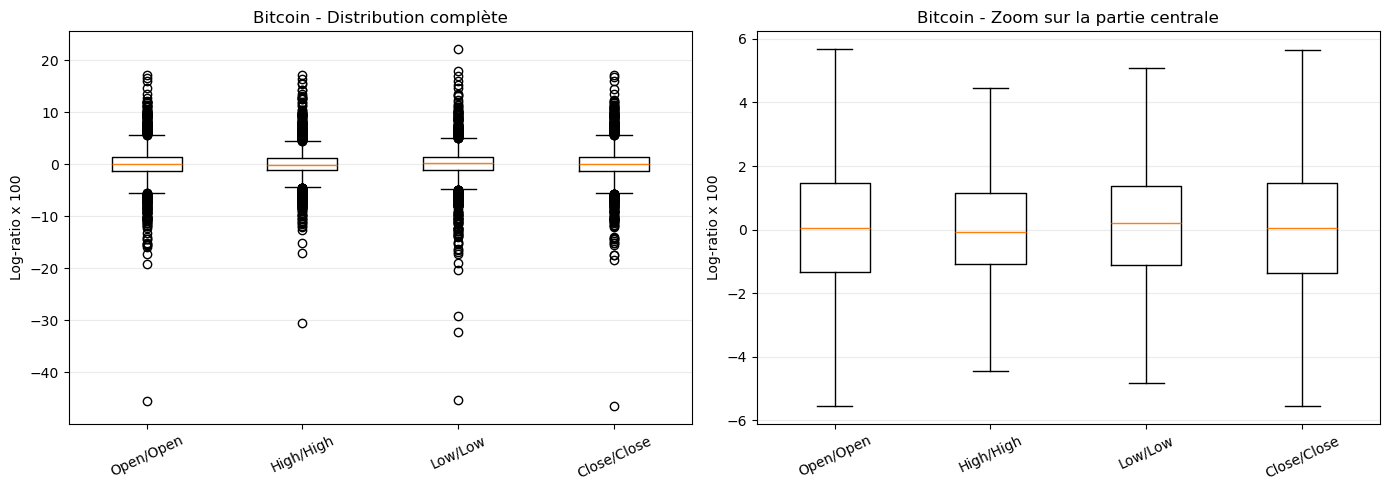

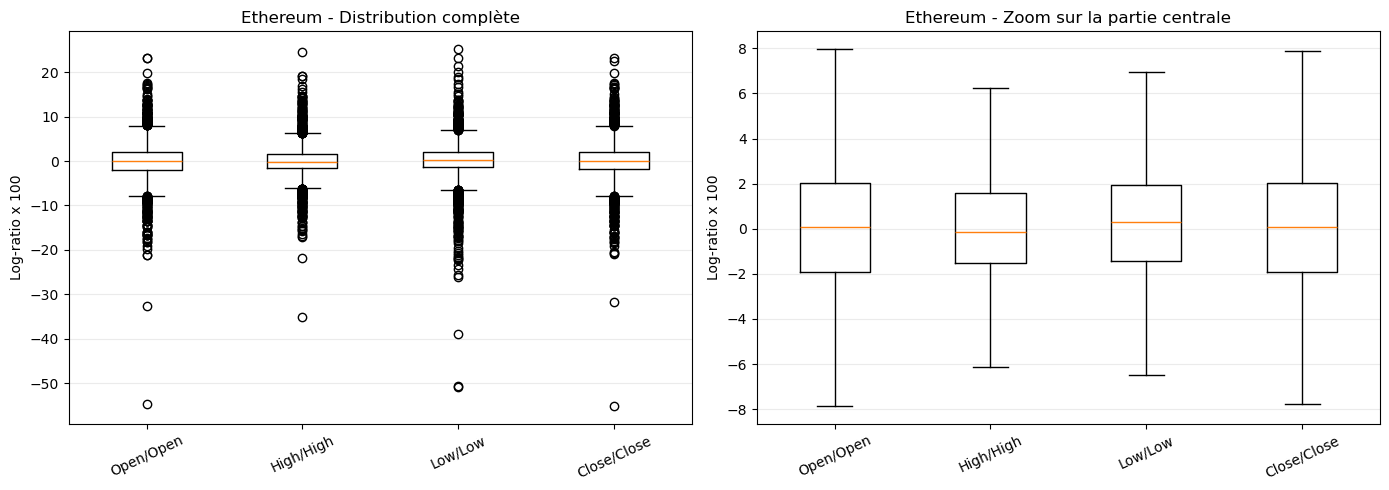

In [37]:

import matplotlib.pyplot as plt

rendements_ohlc = [
    "R_Open_Open",
    "R_High_High",
    "R_Low_Low",
    "R_Close_Close"
]

noms = [
    "Open/Open",
    "High/High",
    "Low/Low",
    "Close/Close"
]

for nom, df in [
    ("Bitcoin", btc_analyse),
    ("Ethereum", eth_analyse)
]:
    fig, axes = plt.subplots(
        1, 2, figsize=(14, 5)
    )

    valeurs = [
        df[col].dropna()
        for col in rendements_ohlc
    ]

    axes[0].boxplot(valeurs, tick_labels=noms)
    axes[0].set_title(
        f"{nom} - Distribution complète"
    )

    axes[1].boxplot(
        valeurs,
        tick_labels=noms,
        showfliers=False
    )

    axes[1].set_title(
        f"{nom} - Zoom sur la partie centrale"
    )

    for ax in axes:
        ax.set_ylabel("Log-ratio x 100")
        ax.grid(axis="y", alpha=0.25)
        ax.tick_params(axis="x", rotation=25)

    plt.tight_layout()
    plt.show()


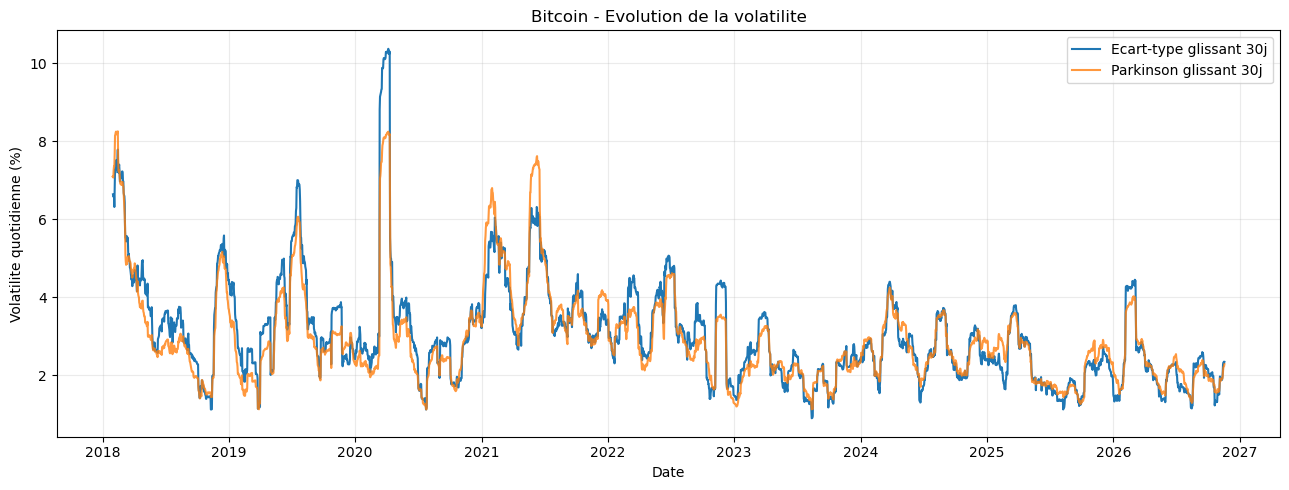


Bitcoin
Ecart-type global : 3.3358
Volatilite 30j mediane : 2.7612
Volatilite 30j maximale : 10.3649
Date du maximum : 2020-04-06


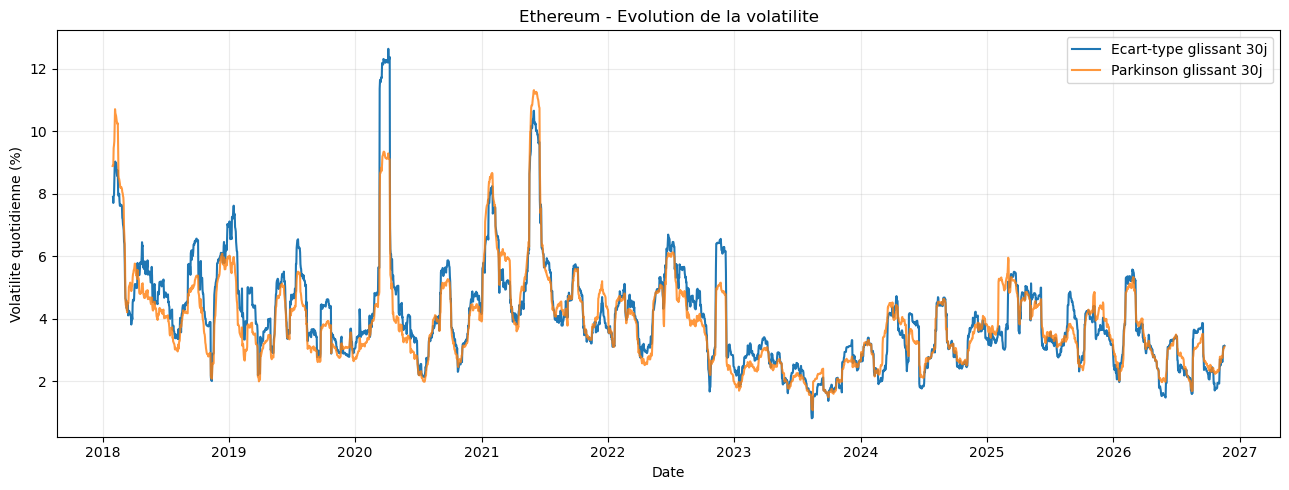


Ethereum
Ecart-type global : 4.3856
Volatilite 30j mediane : 3.7397
Volatilite 30j maximale : 12.6367
Date du maximum : 2020-04-06


In [38]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for nom, df in [
    ("Bitcoin", btc_analyse),
    ("Ethereum", eth_analyse)
]:
    df = df.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").set_index("Date")

    # Rendements logarithmiques x 100
    r = df["R_Close_Close"]

    # Ecart-type glissant sur 30 jours
    volatilite_30 = r.rolling(
        window=30,
        min_periods=30
    ).std()

    # Estimation de Parkinson sur 30 jours
    log_high_low = np.log(df["High"] / df["Low"])

    parkinson_30 = 100 * np.sqrt(
        log_high_low.pow(2).rolling(
            window=30,
            min_periods=30
        ).mean() / (4 * np.log(2))
    )

    plt.figure(figsize=(13, 5))

    plt.plot(
        volatilite_30,
        label="Ecart-type glissant 30j"
    )

    plt.plot(
        parkinson_30,
        label="Parkinson glissant 30j",
        alpha=0.8
    )

    plt.title(f"{nom} - Evolution de la volatilite")
    plt.xlabel("Date")
    plt.ylabel("Volatilite quotidienne (%)")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    print(f"\n{nom}")
    print("Ecart-type global :", round(r.std(), 4))
    print(
        "Volatilite 30j mediane :",
        round(volatilite_30.median(), 4)
    )
    print(
        "Volatilite 30j maximale :",
        round(volatilite_30.max(), 4)
    )
    print(
        "Date du maximum :",
        volatilite_30.idxmax().date()
    )


Bleu — Écart-type des rendements Close/Close

Mesure la dispersion des rendements de clôture sur les 30 derniers jours.




Orange — Estimateur de Parkinson

Estime la volatilité en utilisant les amplitudes High/Low des 30 derniers jours.

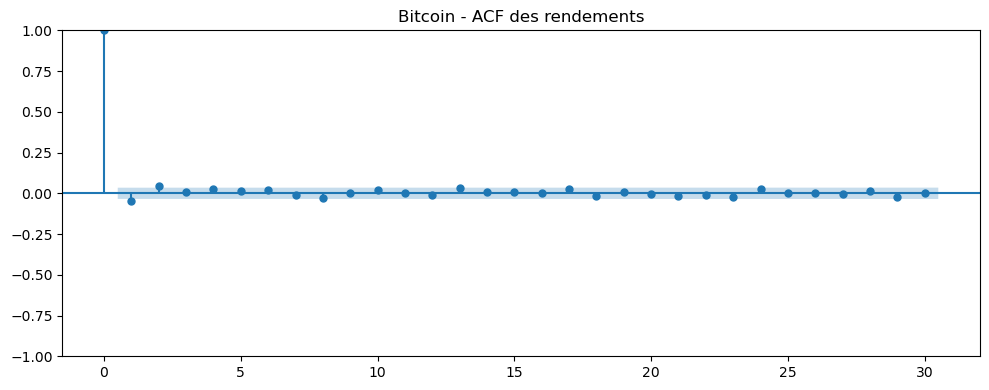

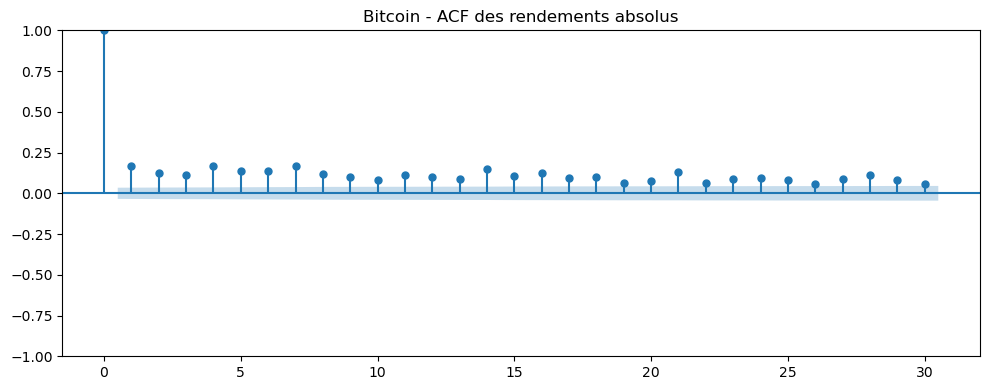

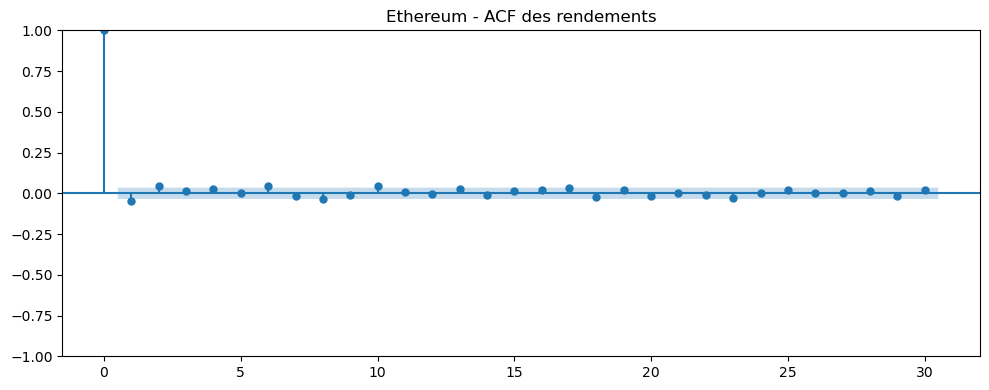

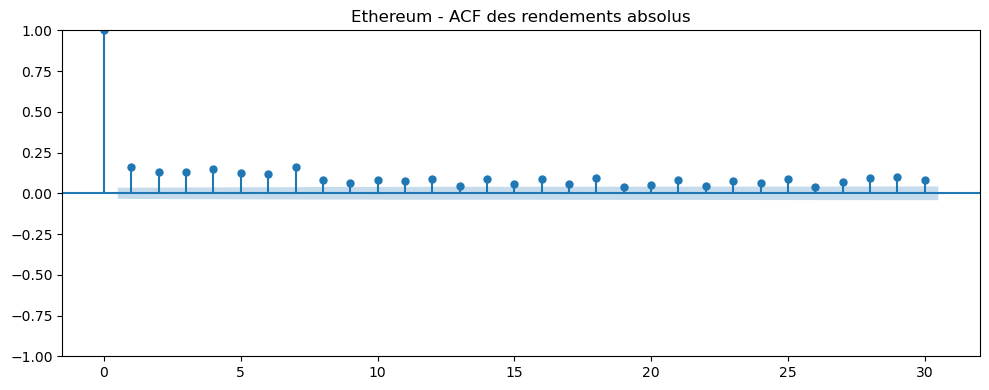

In [40]:

from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

for nom, df in [
    ("Bitcoin", btc_analyse),
    ("Ethereum", eth_analyse)
]:
    r = df["R_Close_Close"].dropna()

    # ACF des rendements
    fig, ax = plt.subplots(figsize=(10, 4))
    plot_acf(r, lags=30, ax=ax)
    ax.set_title(f"{nom} - ACF des rendements")
    plt.tight_layout()
    plt.show()

    # ACF des rendements absolus
    fig, ax = plt.subplots(figsize=(10, 4))
    plot_acf(r.abs(), lags=30, ax=ax)
    ax.set_title(
        f"{nom} - ACF des rendements absolus"
    )
    plt.tight_layout()
    plt.show()


calculer tous les mouvements OHLC

In [35]:

import numpy as np
import pandas as pd


def calculer_variables_ohlc(df):

    df = df.copy()

    df["Date"] = pd.to_datetime(df["Date"])

    df = df.sort_values("Date").reset_index(drop=True)

    colonnes = ["Open", "High", "Low", "Close"]

    for col in colonnes:
        df[col] = pd.to_numeric(df[col], errors="raise")

    if not np.isfinite(df[colonnes].to_numpy()).all():
        raise ValueError("Prix non finis détectés")

    if (df[colonnes] <= 0).any().any():
        raise ValueError("Prix non positifs détectés")

    if df["Date"].duplicated().any():
        raise ValueError("Dates dupliquées")

    O = df["Open"]
    H = df["High"]
    L = df["Low"]
    C = df["Close"]

    if ((H < df[colonnes].max(axis=1)) |
        (L > df[colonnes].min(axis=1))).any():
        raise ValueError("Bougie OHLC incohérente")

    # A. EVOLUTION ENTRE DEUX JOURNEES
    df["R_Open_Open"] = 100 * np.log(O / O.shift(1))
    df["R_High_High"] = 100 * np.log(H / H.shift(1))
    df["R_Low_Low"] = 100 * np.log(L / L.shift(1))
    df["R_Close_Close"] = 100 * np.log(C / C.shift(1))

    # B. MOUVEMENTS A L'INTERIEUR D'UNE JOURNEE
    df["R_Open_Close"] = 100 * np.log(C / O)
    df["Excursion_Open_High"] = 100 * np.log(H / O)
    df["Excursion_Open_Low"] = 100 * np.log(L / O)
    df["Amplitude_High_Low"] = 100 * np.log(H / L)

    # C. MOUVEMENT ENTRE DEUX JOURNEES
    df["Gap"] = 100 * np.log(O / C.shift(1))

    # D. ESTIMATION DE VOLATILITE PAR L'AMPLITUDE
    df["Volatilite_Parkinson"] = (
        100 * np.log(H / L) /
        np.sqrt(4 * np.log(2))
    )

    return df


btc_analyse = calculer_variables_ohlc(btc)
eth_analyse = calculer_variables_ohlc(eth)

print("BITCOIN")
display(btc_analyse.tail())

print("ETHEREUM")
display(eth_analyse.tail())


BITCOIN


,Date,Adj Close,Close,High,Low,Open,Volume,R_Open_Open,R_High_High,R_Low_Low,R_Close_Close,R_Open_Close,Excursion_Open_High,Excursion_Open_Low,Amplitude_High_Low,Gap,Volatilite_Parkinson
3239,2026-11-14,"64,128.05078","64,128.05078","68,377.53906","63,329.42969","68,249.27344",44019244180,-4.43320,-4.36530,-6.60426,-6.22849,-6.22849,0.18776,-7.48166,7.66942,0.00000,4.60596
3240,2026-11-15,"65,305.06250","65,305.06250","66,055.10156","62,017.88281","64,128.05078",39757267458,-6.22849,-3.45551,-2.09274,1.81877,1.81877,2.96074,-3.34591,6.30665,0.00000,3.78753
3241,2026-11-16,"64,855.84375","64,855.84375","65,604.60156","63,834.67188","65,305.06250",31812410118,1.81877,-0.68434,2.88737,-0.69025,-0.69025,0.45763,-2.27731,2.73494,0.00000,1.64250
3242,2026-11-17,"64,893.94531","64,893.94531","65,365.12891","63,284.45703","64,855.84375",34516876177,-0.69025,-0.36569,-0.86567,0.05873,0.05873,0.78219,-2.45273,3.23492,0.00000,1.94277
3243,2026-11-18,"62,987.26562","62,987.26562","64,928.80078","62,017.37891","64,893.94531",30351320839,0.05873,-0.66976,-2.02251,-2.98218,-2.98218,0.05370,-4.53397,4.58766,0.00000,2.75517


ETHEREUM


,Date,Adj Close,Close,High,Low,Open,Volume,R_Open_Open,R_High_High,R_Low_Low,R_Close_Close,R_Open_Close,Excursion_Open_High,Excursion_Open_Low,Amplitude_High_Low,Gap,Volatilite_Parkinson
3239,2026-11-14,"1,769.12048","1,769.12048","1,933.94824","1,730.70459","1,927.58887",17981259090,-4.52569,-4.28655,-9.20336,-8.57874,-8.57874,0.32937,-10.77413,11.10350,0.00000,6.66833
3240,2026-11-15,"1,835.49524","1,835.49524","1,843.14502","1,712.38318","1,769.12048",15785301494,-8.57874,-4.80903,-1.06425,3.68318,3.68318,4.09908,-3.25964,7.35873,0.00000,4.41937
3241,2026-11-16,"1,819.27588","1,819.27588","1,863.96997","1,785.53479","1,835.49524",11738710877,3.68318,1.12352,4.18319,-0.88758,-0.88758,1.53943,-2.75964,4.29906,0.00000,2.58185
3242,2026-11-17,"1,822.96130","1,822.96130","1,840.69507","1,750.46375","1,819.27588",12860752571,-0.88758,-1.25654,-1.98372,0.20237,0.20237,1.17047,-3.85578,5.02625,0.00000,3.01857
3243,2026-11-18,"1,774.74915","1,774.74915","1,824.27454","1,732.70715","1,822.96130",10746861848,0.20237,-0.89609,-1.01957,-2.68032,-2.68032,0.07201,-5.07773,5.14974,0.00000,3.09273


### Cellule 4 — Diagnostic de qualité **avant** le nettoyage
Nous contrôlons la date invalide, la date hors période, les doublons calendaires, les jours manquants, les NaN/infinis, les prix non positifs, le volume négatif et les contraintes de bougies : `High ≥ Open, Close, Low` et `Low ≤ Open, Close, High`.

**Décision :** ces chiffres serviront à justifier toute modification et seront comparés à ceux de la table finale.

In [20]:
bilan_brut = []
for actif, brut in bruts.items():
    dt = pd.to_datetime(brut["Date"], errors="coerce", utc=True).dt.tz_convert(None).dt.normalize()
    v = brut[REQUISES[1:]].apply(pd.to_numeric, errors="coerce")
    fini = pd.Series(np.isfinite(v.to_numpy(dtype=float)).all(axis=1), index=v.index)
    valide = dt.between(DEBUT, FIN)
    dates_presentes = pd.DatetimeIndex(dt[valide].dropna().unique())
    absentes = DATES_ATTENDUES.difference(dates_presentes)
    high_incoherent = v["High"] < v[["Open", "Low", "Close"]].max(axis=1)
    low_incoherent = v["Low"] > v[["Open", "High", "Close"]].min(axis=1)
    rapport = {
        "Actif": actif, "Lignes initiales": len(brut),
        "Dates invalides": int(dt.isna().sum()),
        "Dates hors période": int((dt.notna() & ~valide).sum()),
        "Dates dupliquées (lignes)": int(dt[dt.notna()].duplicated(keep=False).sum()),
        "Jours absents": len(absentes),
        "Lignes avec non-finis": int((~fini).sum()),
        "Prix non positifs": int((v[PRIX] <= 0).any(axis=1).sum()),
        "High incohérent": int(high_incoherent.sum()),
        "Low incohérent": int(low_incoherent.sum()),
        "Volumes négatifs": int((v["Volume"] < 0).sum()),
        "Volumes nuls (alerte)": int((v["Volume"] == 0).sum()),
    }
    bilan_brut.append(rapport)
bilan_brut = pd.DataFrame(bilan_brut).set_index("Actif")
display(bilan_brut)
for actif in bilan_brut.index:
    r = bilan_brut.loc[actif]
    print(f"{actif} : {int(r['Jours absents'])} jour(s) absent(s), "
          f"{int(r['Dates dupliquées (lignes)'])} ligne(s) sur date dupliquée ; "
          f"{int(r['Lignes avec non-finis'])} ligne(s) non finie(s).")
print("Ces diagnostics sont descriptifs : la résolution des anomalies intervient en phase 3.")

,Lignes initiales,Dates invalides,Dates hors période,Dates dupliquées (lignes),Jours absents,Lignes avec non-finis,Prix non positifs,High incohérent,Low incohérent,Volumes négatifs,Volumes nuls (alerte)
Actif,,,,,,,,,,,
BTC,3244,0,0,0,0,0,0,0,0,0,0
ETH,3244,0,0,0,0,0,0,0,0,0,0


BTC : 0 jour(s) absent(s), 0 ligne(s) sur date dupliquée ; 0 ligne(s) non finie(s).
ETH : 0 jour(s) absent(s), 0 ligne(s) sur date dupliquée ; 0 ligne(s) non finie(s).
Ces diagnostics sont descriptifs : la résolution des anomalies intervient en phase 3.


### Cellule 5 — Graphiques des prix et des volumes (données brutes)
Les séries permettent de visualiser les cycles et les changements d'activité. **Un fort mouvement de prix n'est pas un motif de suppression.** Les graphiques ne constituent pas, à eux seuls, une preuve de régime HMM.

**Lecture :** repérer des ruptures, des périodes calmes et des pics de volume à approfondir.

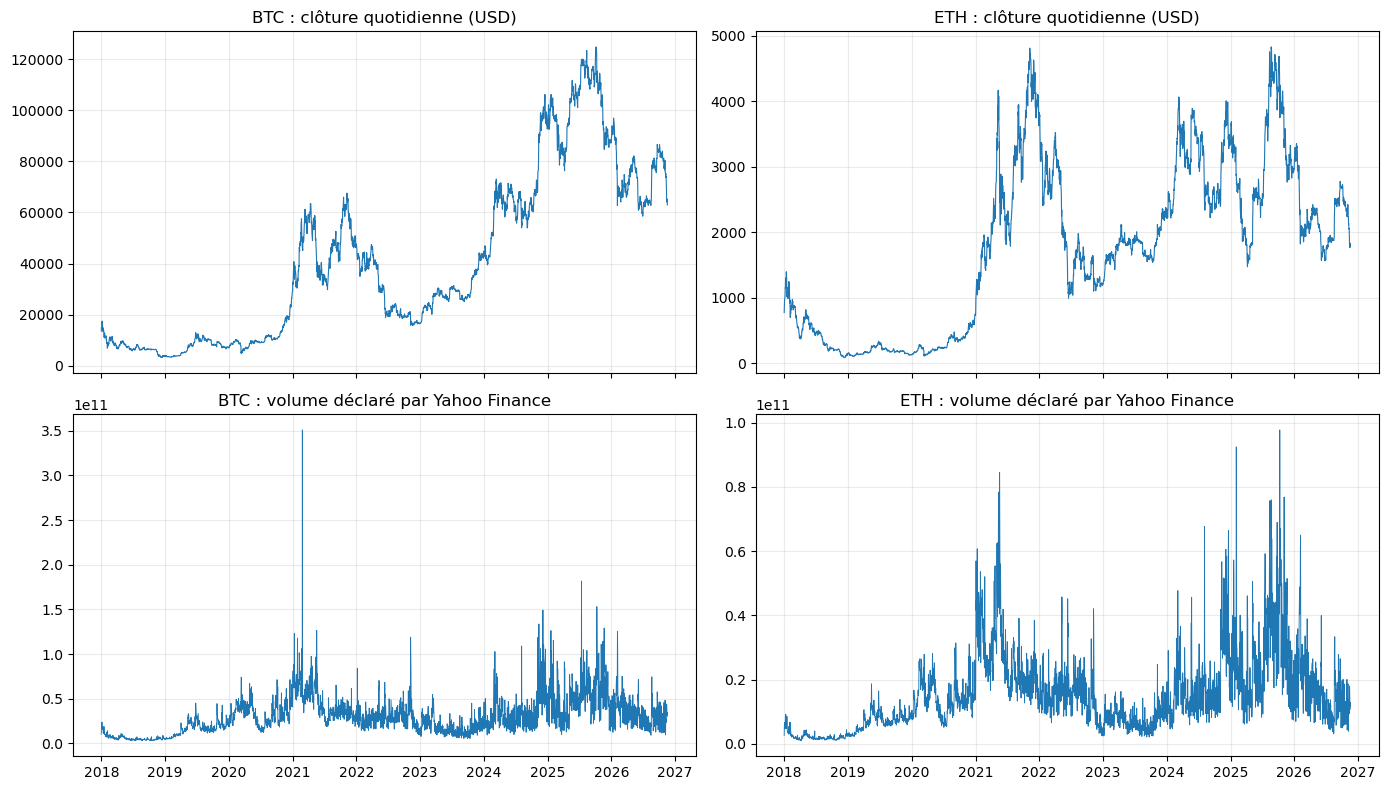

Interprétation : comparer les périodes visibles et les pics avec le rapport qualité ; ne pas conclure à partir du prix seul.


In [21]:
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex="col")
for j, (actif, brut) in enumerate(bruts.items()):
    dt = pd.to_datetime(brut["Date"], errors="coerce", utc=True).dt.tz_convert(None)
    close = pd.to_numeric(brut["Close"], errors="coerce")
    volume = pd.to_numeric(brut["Volume"], errors="coerce")
    mask = dt.between(DEBUT, FIN)
    axes[0, j].plot(dt[mask], close[mask], linewidth=.8)
    axes[0, j].set_title(f"{actif} : clôture quotidienne (USD)")
    axes[1, j].plot(dt[mask], volume[mask], linewidth=.65)
    axes[1, j].set_title(f"{actif} : volume déclaré par Yahoo Finance")
    for ax in axes[:, j]: ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "prix_et_volumes.png", dpi=140)
plt.show()
print("Interprétation : comparer les périodes visibles et les pics avec le rapport qualité ; ne pas conclure à partir du prix seul.")

### Cellule 6 — Construction d'une vue exploratoire des rendements (sans nettoyage définitif)

**Pourquoi cette étape est-elle dans Data Understanding ?** Pour calculer les histogrammes, les boîtes à moustaches et les tests de lois sur les **rendements**, nous avons besoin d'observations numériques utilisables. Nous construisons ici un **sous-ensemble d'exploration en mémoire** : aucune donnée originale n'est effacée et aucun CSV nettoyé n'est encore produit.

- Les dates dupliquées sont mises de côté pour cette exploration, **même si les deux lignes diffèrent** : nous ne choisissons pas arbitrairement une valeur.
- Les observations de prix non positifs, de valeurs non finies, de volume négatif ou de bougies impossibles sont mises de côté uniquement dans la vue exploratoire.
- Les hausses ou les baisses extrêmes **valides** restent conservées.
- Un rendement n'est calculé que si les deux dates sont **consécutives**.

La formule du rendement logarithmique en points de pourcentage est :

\[r_t = 100\ln\left(\frac{P_t}{P_{t-1}}\right).\]

**Interprétation :** les tailles des vues exploratoires servent à qualifier la fiabilité des statistiques ; les anomalies seront reprises et journalisées dans la phase 3.

In [22]:
# Vue de travail EXPLORATOIRE : rien n'est modifié dans data/raw ni sauvegardé en data/processed.
vues_exploratoires = {}
rendements = {}
resume_exploration = []

for actif, brut in bruts.items():
    vue = brut[REQUISES].copy()
    vue["Date"] = pd.to_datetime(vue["Date"], errors="coerce", utc=True).dt.tz_convert(None).dt.normalize()
    for col in REQUISES[1:]:
        vue[col] = pd.to_numeric(vue[col], errors="coerce")

    # Vérifications de validité, seulement pour calculer des statistiques d'exploration.
    dates_valides = vue["Date"].between(DEBUT, FIN)
    dates_uniques = ~vue["Date"].duplicated(keep=False)
    valeurs_finies = np.isfinite(vue[REQUISES[1:]].to_numpy(dtype=float)).all(axis=1)
    prix_valides = (vue[PRIX] > 0).all(axis=1)
    volumes_valides = vue["Volume"] >= 0
    high_valide = vue["High"] >= vue[["Open", "Low", "Close"]].max(axis=1)
    low_valide = vue["Low"] <= vue[["Open", "High", "Close"]].min(axis=1)

    admissibles = (dates_valides & dates_uniques & valeurs_finies & prix_valides
                   & volumes_valides & high_valide & low_valide)
    vue_ok = vue.loc[admissibles].sort_values("Date").set_index("Date")
    vues_exploratoires[actif] = vue_ok

    close = vue_ok["Close"]
    r = 100 * np.log(close / close.shift(1))
    r = r.where(close.index.to_series().diff() == pd.Timedelta(days=1))
    rendements[actif] = r.rename(actif)

    resume_exploration.append({
        "Actif": actif,
        "Lignes brutes": len(brut),
        "Journées admissibles (EDA)": len(vue_ok),
        "Lignes exclues de la vue temporaire": int((~admissibles).sum()),
        "Rendements quotidiens disponibles": int(r.notna().sum()),
    })

rapport_eda = pd.DataFrame(resume_exploration).set_index("Actif")
display(rapport_eda)

rendements_df = pd.concat(rendements.values(), axis=1).sort_index()
paire = rendements_df[["BTC", "ETH"]].dropna()
print("Journées communes BTC/ETH exploitables :", len(paire))
display(rendements_df.head(7))
assert len(paire) > 30, "Nombre insuffisant de rendements communs pour l'exploration"
print("Vue exploratoire uniquement : le nettoyage et les sauvegardes auront lieu en phase 3.")

,Lignes brutes,Journées admissibles (EDA),Lignes exclues de la vue temporaire,Rendements quotidiens disponibles
Actif,,,,
BTC,3244,3244,0,3243
ETH,3244,3244,0,3243


Journées communes BTC/ETH exploitables : 3243


,BTC,ETH
Date,,
2018-01-01,NaN,NaN
2018-01-02,9.25893,13.51447
2018-01-03,1.45051,8.48034
2018-01-04,2.58584,1.87304
2018-01-05,11.09445,1.69797
2018-01-06,0.55784,4.31175
2018-01-07,-6.17407,10.16799


Vue exploratoire uniquement : le nettoyage et les sauvegardes auront lieu en phase 3.


### Cellule 7 — Statistiques descriptives des rendements

**Moyenne :** variation moyenne ; **écart-type :** dispersion ; **skewness :** asymétrie ; **kurtosis excédentaire :** importance relative des queues et valeurs extrêmes. Une kurtosis élevée appelle à vérifier l'adéquation de la loi normale, mais n'identifie pas à elle seule un régime de panique.

In [23]:
descriptions = []
for actif, r in rendements.items():
    x = r.dropna()
    descriptions.append({
        "Actif": actif, "N": len(x), "Moyenne_%": x.mean(),
        "Médiane_%": x.median(), "Écart_type_%": x.std(),
        "Minimum_%": x.min(), "Maximum_%": x.max(),
        "Skewness": stats.skew(x, bias=False),
        "Excès_kurtosis": stats.kurtosis(x, fisher=True, bias=False),
        "P01_%": x.quantile(.01), "P99_%": x.quantile(.99)
    })
statistiques = pd.DataFrame(descriptions).set_index("Actif")
display(statistiques)
for actif, s in statistiques.iterrows():
    biais = "vers les pertes" if s["Skewness"] < -0.2 else "vers les gains" if s["Skewness"] > .2 else "faible"
    queues = "plus lourdes qu'une normale au sens du 4e moment" if s["Excès_kurtosis"] > 0 else "pas plus lourdes selon ce seul indicateur"
    print(f"{actif} : moyenne {s['Moyenne_%']:.3f}%/j, dispersion {s['Écart_type_%']:.3f} points ; "
          f"asymétrie {biais}, excès de kurtosis {s['Excès_kurtosis']:.2f} ({queues}).")

,N,Moyenne_%,Médiane_%,Écart_type_%,Minimum_%,Maximum_%,Skewness,Excès_kurtosis,P01_%,P99_%
Actif,,,,,,,,,,
BTC,3243,0.04714,0.04629,3.33584,-46.47302,17.18206,-0.94022,14.92440,-10.16137,9.66485
ETH,3243,0.02564,0.05671,4.38564,-55.07317,23.06952,-0.82185,11.15387,-13.36086,12.07886


BTC : moyenne 0.047%/j, dispersion 3.336 points ; asymétrie vers les pertes, excès de kurtosis 14.92 (plus lourdes qu'une normale au sens du 4e moment).
ETH : moyenne 0.026%/j, dispersion 4.386 points ; asymétrie vers les pertes, excès de kurtosis 11.15 (plus lourdes qu'une normale au sens du 4e moment).


### Cellule 8 — Boxplots (boîtes à moustaches) et valeurs atypiques

Un boxplot représente les quartiles et la médiane. La convention habituelle considère « atypique » une valeur au-delà de \(Q_1-1{,}5 IQR\) ou \(Q_3+1{,}5 IQR\), où \(IQR=Q_3-Q_1\).

**Interprétation :** les points hors moustaches ne sont **pas automatiquement des erreurs**. Dans les marchés crypto, des variations extrêmes peuvent être les épisodes les plus informatifs.

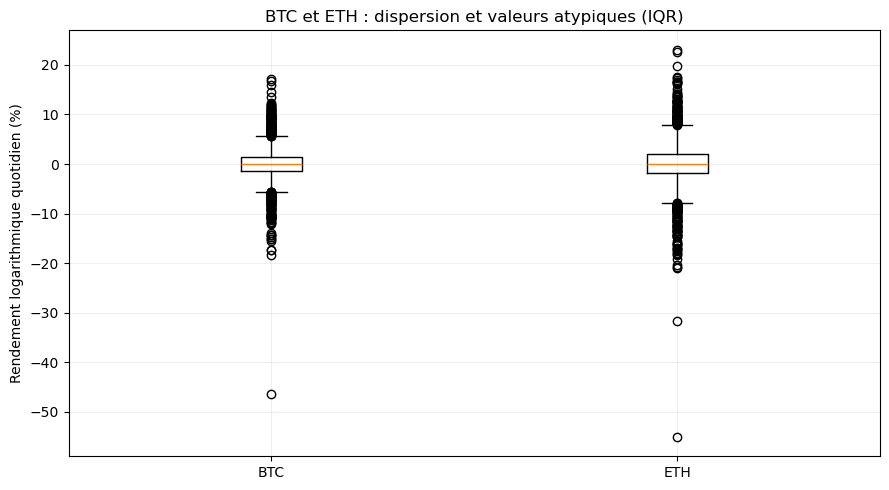

BTC : 270 rendement(s) atypique(s) selon 1,5×IQR sur 3243. Aucune suppression automatique.
ETH : 231 rendement(s) atypique(s) selon 1,5×IQR sur 3243. Aucune suppression automatique.


In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([rendements[a].dropna().to_numpy() for a in ACTIFS], tick_labels=list(ACTIFS))
ax.set_ylabel("Rendement logarithmique quotidien (%)")
ax.set_title("BTC et ETH : dispersion et valeurs atypiques (IQR)")
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(FIG_DIR / "boxplots_rendements.png", dpi=140)
plt.show()
for actif, r in rendements.items():
    x = r.dropna()
    q1, q3 = x.quantile([.25, .75])
    iqr = q3 - q1
    atypiques = x[(x < q1-1.5*iqr) | (x > q3+1.5*iqr)]
    print(f"{actif} : {len(atypiques)} rendement(s) atypique(s) selon 1,5×IQR sur {len(x)}. "
          "Aucune suppression automatique.")

### Cellule 9 — Matrices de covariance et de corrélation BTC/ETH

La **covariance** indique comment les rendements varient ensemble, mais dépend des unités et de l'échelle. La **corrélation** standardise cette relation entre −1 et +1.

**Précaution :** ces matrices sont calculées sur les *mêmes dates* pour les deux actifs. Une forte corrélation ne prouve pas une causalité et ne signifie pas que leurs niveaux de prix sont identiques.

**Lien HMM futur :** avec des émissions gaussiennes multivariées, une matrice de covariance pourra être estimée *conditionnellement à chaque état*. Ce n'est pas la même chose que la covariance globale ci-dessous.

Matrice de covariance des rendements (points de % au carré) :


,BTC,ETH
BTC,11.12780,12.14381
ETH,12.14381,19.23385


Matrice de corrélation des rendements :


,BTC,ETH
BTC,1.00000,0.83007
ETH,0.83007,1.00000


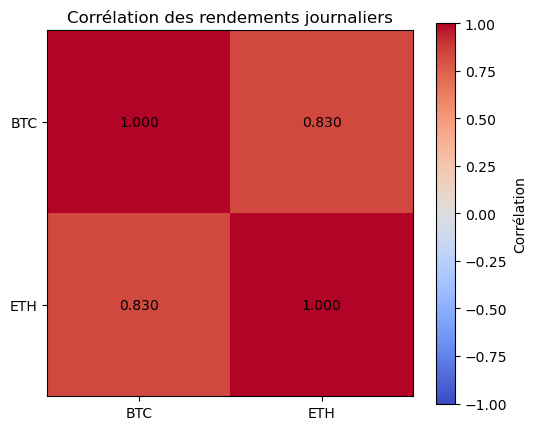

Interprétation : corrélation linéaire positive (0.830) sur 3243 dates communes.


In [25]:
covariance = paire.cov()
correlation = paire.corr()
print("Matrice de covariance des rendements (points de % au carré) :")
display(covariance)
print("Matrice de corrélation des rendements :")
display(correlation)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(correlation.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(2), labels=correlation.columns)
ax.set_yticks(range(2), labels=correlation.index)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{correlation.iloc[i,j]:.3f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Corrélation")
ax.set_title("Corrélation des rendements journaliers")
fig.tight_layout()
fig.savefig(FIG_DIR / "correlation_BTC_ETH.png", dpi=140)
plt.show()
rho = float(correlation.loc["BTC", "ETH"])
relation = "positive" if rho > 0 else "négative" if rho < 0 else "nulle"
print(f"Interprétation : corrélation linéaire {relation} ({rho:.3f}) sur {len(paire)} dates communes.")

### Cellule 10 — Histogrammes + densités théoriques
Nous ajustons quatre familles **continues** aux rendements : **normale**, **Student-t**, **Laplace** et **logistique**.

La comparaison visuelle porte sur le centre, l'asymétrie éventuelle et surtout les queues. Les densités sont estimées sur les mêmes rendements que l'histogramme : ce sont des **ajustements descriptifs**, pas une validation hors échantillon.

**Attention :** aucune de ces quatre lois symétriques ne capture toutes les asymétries possibles. Une loi de Student-t peut représenter des queues plus épaisses que la normale.

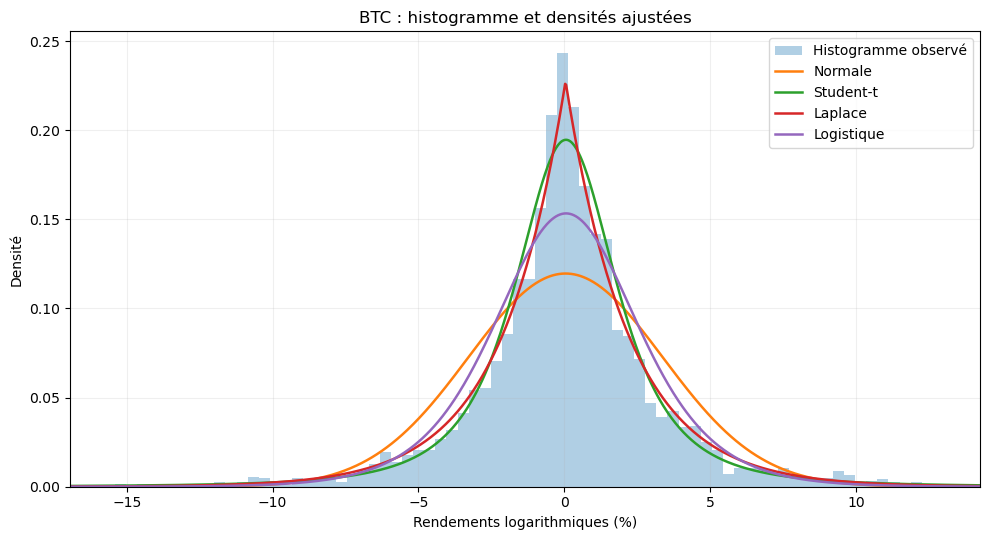

BTC : le graphique est zoomé entre les quantiles 0,1 % et 99,9 %. Les extrêmes restent dans l'échantillon et n'ont pas été supprimés.


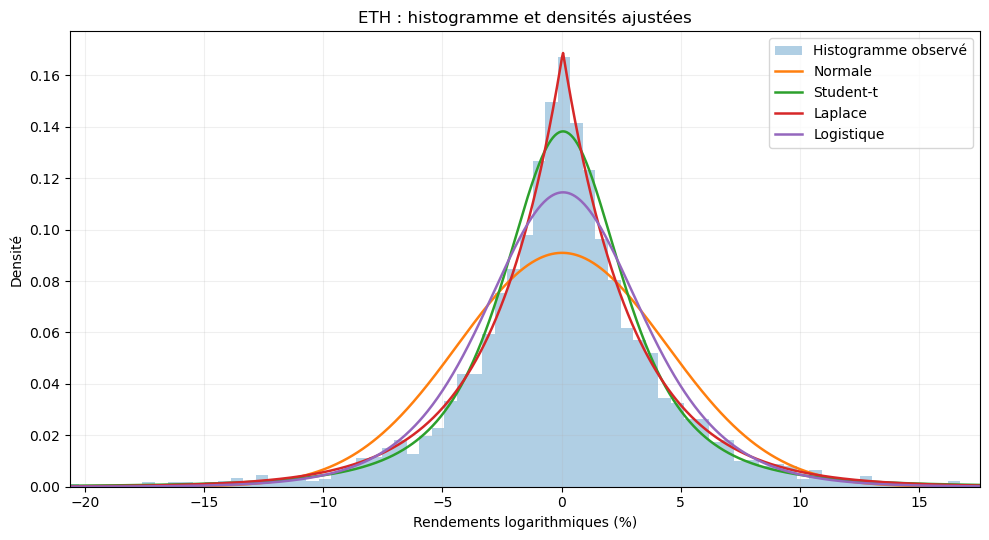

ETH : le graphique est zoomé entre les quantiles 0,1 % et 99,9 %. Les extrêmes restent dans l'échantillon et n'ont pas été supprimés.


In [26]:
LOIS = {"Normale": stats.norm, "Student-t": stats.t,
        "Laplace": stats.laplace, "Logistique": stats.logistic}
parametres_ajustes = {}
for actif, r in rendements.items():
    x = r.dropna().to_numpy(dtype=float)
    parametres_ajustes[actif] = {nom: tuple(loi.fit(x)) for nom, loi in LOIS.items()}
    xs = np.linspace(np.quantile(x, .001), np.quantile(x, .999), 900)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.hist(x, bins="fd", density=True, alpha=.35, label="Histogramme observé")
    for nom, loi in LOIS.items():
        ax.plot(xs, loi.pdf(xs, *parametres_ajustes[actif][nom]), lw=1.8, label=nom)
    ax.set_xlim(xs.min(), xs.max())
    ax.set_xlabel("Rendements logarithmiques (%)")
    ax.set_ylabel("Densité")
    ax.set_title(f"{actif} : histogramme et densités ajustées")
    ax.legend()
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{actif}_histogramme_densites.png", dpi=140)
    plt.show()
    print(f"{actif} : le graphique est zoomé entre les quantiles 0,1 % et 99,9 %. "
          "Les extrêmes restent dans l'échantillon et n'ont pas été supprimés.")

### Cellule 11 — Q-Q plots (quantiles observés contre quantiles théoriques)

Si la loi proposée décrit correctement les quantiles observés, les points sont proches de la diagonale \(y=x\). Des écarts marqués dans les extrémités indiquent un désaccord dans les queues.

**Précaution :** la qualité d'ajustement est examinée visuellement. On ne conclut pas que la loi est « vraie » parce que les points semblent alignés.

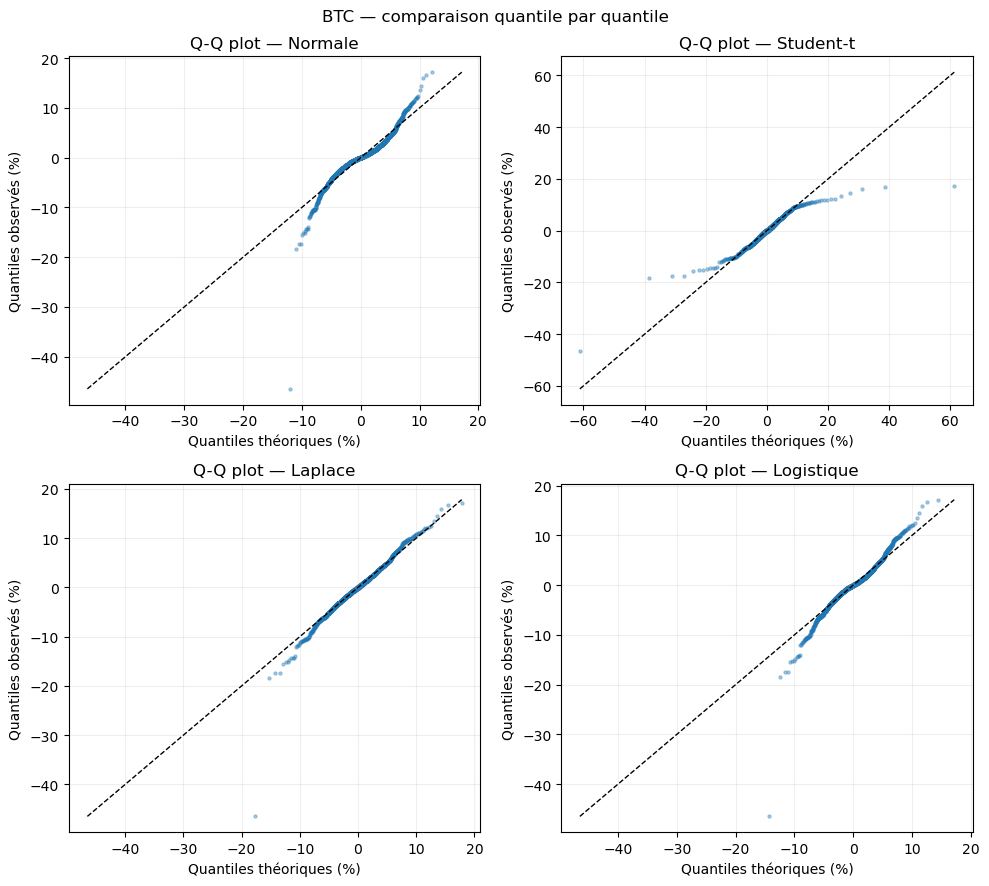

BTC : examine particulièrement les deux extrémités des quatre Q-Q plots.


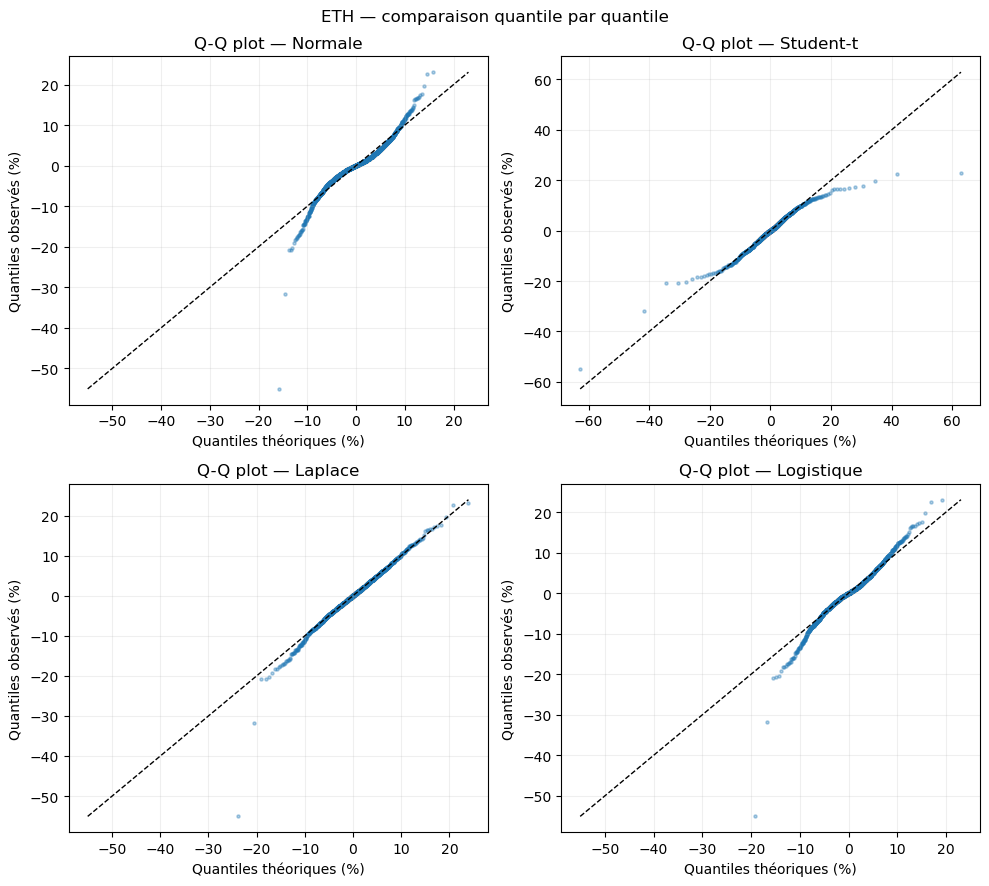

ETH : examine particulièrement les deux extrémités des quatre Q-Q plots.


In [27]:
for actif, r in rendements.items():
    x = np.sort(r.dropna().to_numpy(dtype=float))
    p = (np.arange(1, len(x)+1)-.5) / len(x)
    fig, axes = plt.subplots(2, 2, figsize=(10, 9))
    for ax, (nom, loi) in zip(axes.flat, LOIS.items()):
        theo = loi.ppf(p, *parametres_ajustes[actif][nom])
        ax.scatter(theo, x, s=5, alpha=.35)
        lo = min(np.min(theo), np.min(x))
        hi = max(np.max(theo), np.max(x))
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        ax.set_title(f"Q-Q plot — {nom}")
        ax.set_xlabel("Quantiles théoriques (%)")
        ax.set_ylabel("Quantiles observés (%)")
        ax.grid(alpha=.2)
    fig.suptitle(f"{actif} — comparaison quantile par quantile")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{actif}_qqplots.png", dpi=140)
    plt.show()
    print(f"{actif} : examine particulièrement les deux extrémités des quatre Q-Q plots.")

### Cellule 12 — Tests de Jarque-Bera et Kolmogorov-Smirnov

- **Jarque-Bera** : \(H_0\) = la distribution est normale ; s'appuie sur l'asymétrie et la kurtosis. En grande taille d'échantillon, la statistique est comparée à une loi \(\chi^2(2)\) sous les hypothèses du test.
- **Kolmogorov-Smirnov (KS)** : compare la fonction de répartition empirique à celle d'une loi candidate. Nous le calculons **pour chacune des quatre lois**.
- **Point méthodologique essentiel :** puisque les paramètres des lois sont estimés sur les données analysées, nous utilisons `scipy.stats.goodness_of_fit(..., statistic="ks")` qui calibre la p-value par simulation et réestimation.

Avec `N_MC = 99`, la résolution des p-values est de 0,01 ; pour une étude plus approfondie, augmenter à **999 ou plus**, au prix d'un temps de calcul supérieur. Les hypothèses usuelles d'observations indépendantes sont discutables en finance : les p-values sont ici **exploratoires**. Une p-value élevée ne prouve pas que la loi est correcte, et tester plusieurs lois augmente le risque de décisions trompeuses.

**Cette cellule est plus lente** que les précédentes. Pour un test rapide : définir la variable d'environnement `HMM_KS_SIMULATIONS=19` avant de lancer le notebook ; ne pas utiliser ce réglage pour conclure au seuil de 5 %.

In [28]:
N_MC = int(os.getenv("HMM_KS_SIMULATIONS", "99"))
if N_MC < 19:
    raise ValueError("Utiliser au moins 19 simulations Monte-Carlo pour cette exploration")
SEUIL = .05
tests_distribution = []
for actif, r in rendements.items():
    x = r.dropna().to_numpy(dtype=float)
    jb = stats.jarque_bera(x)
    print(f"\n{actif} — Jarque-Bera : JB={jb.statistic:.4f}, p={jb.pvalue:.6g} → "
          + ("normalité rejetée" if jb.pvalue < SEUIL else "normalité non rejetée"))
    for nom, loi in LOIS.items():
        test = stats.goodness_of_fit(loi, x, statistic="ks", n_mc_samples=N_MC,
                                     rng=np.random.default_rng(12345))
        tests_distribution.append({
            "Actif": actif, "Loi": nom, "KS_D": float(test.statistic),
            "KS_pvalue_MC": float(test.pvalue),
            "Decision_KS_5pct": "Rejet" if test.pvalue < SEUIL else "Non rejet",
            "JB_pvalue_normale": float(jb.pvalue) if nom == "Normale" else np.nan,
            "Simulations_MC": N_MC,
        })
resultats_tests = pd.DataFrame(tests_distribution)
display(resultats_tests)
resultats_tests.to_csv(REPORT_DIR / "tests_distributions_exploratoires.csv", index=False)
print("Lecture : plus D est petit, plus la distance ECDF-CDF est faible pour la loi ajustée.")
print("Une non-rejection ne démontre pas la loi ; les dépendances temporelles affectent l'interprétation des p-values.")


BTC — Jarque-Bera : JB=30474.6501, p=0 → normalité rejetée

ETH — Jarque-Bera : JB=17118.1281, p=0 → normalité rejetée


,Actif,Loi,KS_D,KS_pvalue_MC,Decision_KS_5pct,JB_pvalue_normale,Simulations_MC
0,BTC,Normale,0.09228,0.01000,Rejet,0.00000,99
1,BTC,Student-t,0.01968,0.01000,Rejet,NaN,99
2,BTC,Laplace,0.02018,0.01000,Rejet,NaN,99
3,BTC,Logistique,0.05215,0.01000,Rejet,NaN,99
4,ETH,Normale,0.08193,0.01000,Rejet,0.00000,99
5,ETH,Student-t,0.02021,0.01000,Rejet,NaN,99
6,ETH,Laplace,0.01135,0.50000,Non rejet,NaN,99
7,ETH,Logistique,0.04431,0.01000,Rejet,NaN,99


Lecture : plus D est petit, plus la distance ECDF-CDF est faible pour la loi ajustée.
Une non-rejection ne démontre pas la loi ; les dépendances temporelles affectent l'interprétation des p-values.


### Cellule 13 — Dépendance temporelle : autocorrélation (ACF) et ADF

- **ACF des rendements** : mesure la dépendance linéaire entre rendements séparés par plusieurs jours.
- **ACF des rendements absolus** : peut révéler des *regroupements de volatilité* (périodes agitées qui se succèdent).
- **ADF (Augmented Dickey-Fuller)** : examine la présence d'une racine unitaire, avec \(H_0\) = racine unitaire. Le rejet ne prouve pas toutes les formes de stationnarité.

**Attention :** ces tests supposent un calendrier régulier. Si des dates sont absentes, nous ne traitons pas les écarts de plusieurs jours comme un seul jour. Les p-values classiques restent sensibles aux hypothèses temporelles et à l'hétéroscédasticité.

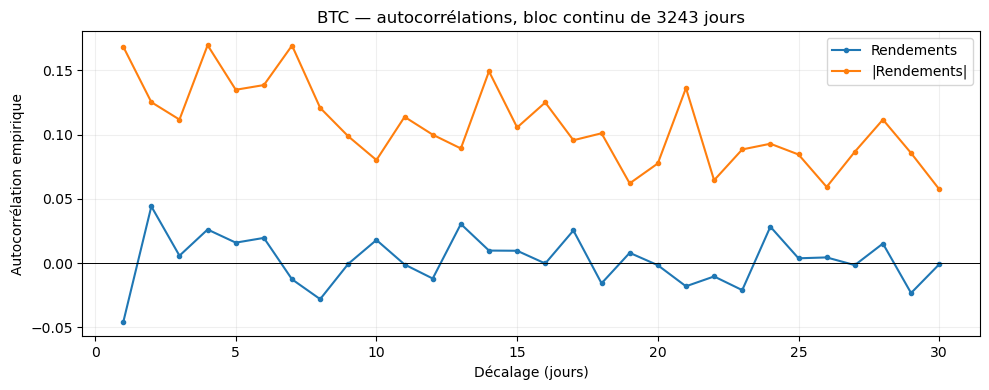

BTC : ACF(1) r=-0.046 ; ACF(1) |r|=0.169 ; ADF=-19.894, p=0.
ADF : racine unitaire rejetée au seuil 5 %


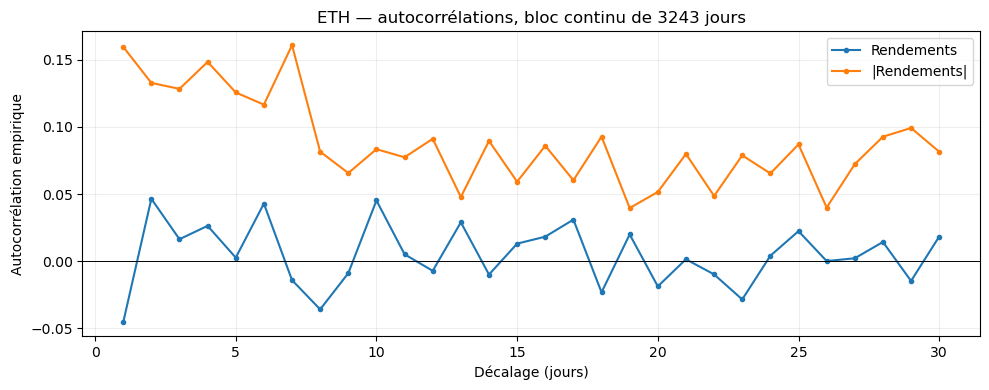

ETH : ACF(1) r=-0.046 ; ACF(1) |r|=0.160 ; ADF=-17.265, p=5.91247e-30.
ADF : racine unitaire rejetée au seuil 5 %


In [29]:
from statsmodels.tsa.stattools import adfuller

for actif, serie in rendements.items():
    # Échantillon continu le plus long si des jours sont absents.
    s = serie.dropna()
    blocs = (s.index.to_series().diff().ne(pd.Timedelta(days=1))).cumsum()
    plus_long = s.groupby(blocs).apply(lambda bloc: len(bloc)).idxmax()
    x = s[blocs == plus_long]
    if len(x) < 40:
        print(f"{actif} : bloc continu trop court pour ACF/ADF")
        continue
    lags = list(range(1, min(30, len(x)//4)+1))
    acf_ret = [x.autocorr(lag=k) for k in lags]
    acf_abs = [x.abs().autocorr(lag=k) for k in lags]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(lags, acf_ret, marker="o", ms=3, label="Rendements")
    ax.plot(lags, acf_abs, marker="o", ms=3, label="|Rendements|")
    ax.axhline(0, color="black", lw=.7)
    ax.set_xlabel("Décalage (jours)")
    ax.set_ylabel("Autocorrélation empirique")
    ax.set_title(f"{actif} — autocorrélations, bloc continu de {len(x)} jours")
    ax.legend()
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{actif}_autocorrelations.png", dpi=140)
    plt.show()
    adf = adfuller(x.to_numpy(), autolag="AIC")
    print(f"{actif} : ACF(1) r={acf_ret[0]:.3f} ; ACF(1) |r|={acf_abs[0]:.3f} ; "
          f"ADF={adf[0]:.3f}, p={adf[1]:.6g}.")
    print("ADF : racine unitaire rejetée au seuil 5 %" if adf[1]<.05 else
          "ADF : racine unitaire non rejetée au seuil 5 %")

### Cellule 14 — ACP exploratoire (optionnelle)

L'**Analyse en Composantes Principales** transforme plusieurs variables corrélées en axes orthogonaux qui expliquent une part décroissante de la variance. Avec seulement **deux rendements BTC et ETH**, l'ACP est principalement **pédagogique** : elle ne sera pas automatiquement incluse dans un futur HMM, car elle réduit l'interprétabilité économique.

Pour éviter de calculer les paramètres de standardisation et de l'ACP sur le futur, nous les **ajustons exclusivement sur 2018–2024**, puis appliquons la même transformation aux données ultérieures. Nous ne faisons aucune évaluation de trading dans cette cellule.

Si nous ajoutons RSI, MACD et volatilité plus tard, une ACP pourrait être réétudiée avec davantage de variables.

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

jeu_train = paire.loc[paire.index <= pd.Timestamp("2024-12-31")]
if len(jeu_train) < 30:
    print("ACP non exécutée : données d'apprentissage insuffisantes")
else:
    scaler = StandardScaler().fit(jeu_train)
    pca = PCA(n_components=2).fit(scaler.transform(jeu_train))
    poids = pd.DataFrame(pca.components_.T, index=paire.columns, columns=["PC1", "PC2"])
    variance = pd.Series(pca.explained_variance_ratio_, index=["PC1", "PC2"], name="Variance expliquée")
    print("ACP ajustée UNIQUEMENT sur 2018-2024 :")
    display(poids)
    display((100*variance).round(2).to_frame("Variance expliquée (%)"))
    transformed = pca.transform(scaler.transform(paire))
    print(f"Projection des {len(transformed)} journées communes ; aucun modèle prédictif entraîné.")
    print("L'interprétation d'un axe dépend des poids PC1/PC2 ; ne pas lui attribuer automatiquement le sens 'bullish' ou 'panique'.")

ACP ajustée UNIQUEMENT sur 2018-2024 :


,PC1,PC2
BTC,0.70711,0.70711
ETH,0.70711,-0.70711


,Variance expliquée (%)
PC1,91.43000
PC2,8.57000


Projection des 3243 journées communes ; aucun modèle prédictif entraîné.
L'interprétation d'un axe dépend des poids PC1/PC2 ; ne pas lui attribuer automatiquement le sens 'bullish' ou 'panique'.


### Bilan de la phase 2 — Ce que nous savons avant le nettoyage

À ce stade, nous avons **exploré** les sources (dates, dimensions, cohérence), puis les rendements sur une vue temporaire. Nous avons examiné leur distribution, les valeurs atypiques, la relation BTC/ETH et les propriétés temporelles. Ces résultats aident à **justifier les règles de préparation** mais ne les remplacent pas.

**Décisions pour la phase 3 :** conserver les CSV bruts ; trier les dates et uniformiser les types ; écarter en quarantaine les lignes OHLCV impossibles ou contradictoires ; ne jamais supprimer une forte variation valide simplement parce qu'elle est atypique ; enregistrer les fichiers préparés et les compteurs d'anomalies.

Les tests de lois sont **exploratoires**, notamment parce que les observations financières peuvent être dépendantes. L'ACP est facultative et ne conditionne pas le nettoyage.

---
## Phase 3 — Data Preparation (préparation et nettoyage définitif)

**Objectif :** transformer la source brute en un jeu de données cohérent, reproductible et auditable.

### Stratégie de nettoyage conservatrice
1. **Ne jamais modifier les CSV d'origine** dans `data/raw/`.
2. Convertir les dates et les colonnes numériques ; contrôler les valeurs non finies.
3. Pour les doublons **strictement identiques**, conserver une seule observation et journaliser les autres.
4. Pour une **date avec plusieurs observations contradictoires**, mettre les lignes de cette date en quarantaine sans arbitrage silencieux.
5. Mettre en quarantaine les lignes de prix non positifs, volume négatif ou incohérence OHLCV.
6. Signaler les journées absentes, sans inventer de prix ni interpoler automatiquement.
7. **Conserver les krachs et les rendements extrêmes techniquement valides.**
8. Sauvegarder les fichiers préparés dans `data/processed/` et les rapports dans `outputs/qualite/`.

Un **boxplot atypique** ou un **test statistique défavorable** ne constitue **pas une justification de suppression**.

### Cellule 15 — Nettoyer et journaliser toutes les décisions
Cette cellule produit un tableau de qualité, les fichiers préparés et les journaux des anomalies. Elle préserve les observations de marché valides, même si elles sont extrêmes.

**Interprétation :** le nombre de lignes en sortie doit être expliqué par les causes d'exclusion. Une date sans observation n'est pas artificiellement comblée.

In [31]:
def preparer_actif(actif, brut):
    df = brut.copy()
    df["_ligne_source"] = df.index + 2  # Numéro de ligne CSV (en-tête = ligne 1)
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce", utc=True).dt.tz_convert(None).dt.normalize()
    for colonne in REQUISES[1:]:
        df[colonne] = pd.to_numeric(df[colonne], errors="coerce")

    dates_invalides = df["Date"].isna()
    hors_periode = df["Date"].notna() & ~df["Date"].between(DEBUT, FIN)
    est_finie = pd.Series(np.isfinite(df[REQUISES[1:]].to_numpy(dtype=float)).all(axis=1), index=df.index)
    prix_non_positifs = (df[PRIX] <= 0).any(axis=1)
    volume_negatif = df["Volume"] < 0
    high_incoherent = df["High"] < df[["Open", "Low", "Close"]].max(axis=1)
    low_incoherent = df["Low"] > df[["Open", "High", "Close"]].min(axis=1)

    # Reconnaître les doublons exactement identiques AVANT les dates contradictoires.
    doublon_identique = df.duplicated(subset=REQUISES, keep="first")
    unique = df.loc[~doublon_identique].copy()
    contradictoires = unique["Date"].notna() & unique["Date"].duplicated(keep=False)
    date_contradictoire = pd.Series(False, index=df.index)
    date_contradictoire.loc[unique.index] = contradictoires

    motifs = pd.DataFrame({
        "date_invalide": dates_invalides,
        "hors_periode": hors_periode,
        "valeur_non_finie": ~est_finie,
        "prix_non_positif": prix_non_positifs,
        "volume_negatif": volume_negatif,
        "high_incoherent": high_incoherent,
        "low_incoherent": low_incoherent,
        "doublon_identique": doublon_identique,
        "date_contradictoire": date_contradictoire,
    }, index=df.index)
    exclure = motifs.any(axis=1)
    anomalies = df.loc[exclure, ["_ligne_source", *REQUISES]].copy()
    anomalies.insert(0, "Actif", actif)
    anomalies["Motifs"] = motifs.loc[exclure].apply(
        lambda ligne: ", ".join(ligne.index[ligne.to_numpy(dtype=bool)]), axis=1
    )

    propre = (df.loc[~exclure, REQUISES]
                .sort_values("Date", kind="stable")
                .reset_index(drop=True))
    dates_absentes = DATES_ATTENDUES.difference(pd.DatetimeIndex(propre["Date"]))
    gaps = pd.DataFrame({"Actif": actif, "Date_absente": dates_absentes})
    volume_nul = int((propre["Volume"] == 0).sum())

    resume = {
        "Actif": actif,
        "Lignes_brutes": len(df),
        "Lignes_exclues_avec_justification": int(exclure.sum()),
        "Doublons_strictement_identiques": int(doublon_identique.sum()),
        "Lignes_sur_dates_contradictoires": int(date_contradictoire.sum()),
        "Valeurs_non_finies": int((~est_finie).sum()),
        "Prix_non_positifs": int(prix_non_positifs.sum()),
        "High_incoherents": int(high_incoherent.sum()),
        "Low_incoherents": int(low_incoherent.sum()),
        "Volumes_negatifs": int(volume_negatif.sum()),
        "Volumes_nuls_a_examiner": volume_nul,
        "Jours_absents_apres_preparation": len(dates_absentes),
        "Lignes_preparees": len(propre),
        "Etat": "COMPLET" if len(dates_absentes) == 0 and len(propre) == len(DATES_ATTENDUES) else "A_VERIFIER",
    }
    return propre, anomalies, gaps, resume

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
prepares = {}
resumes = []
toutes_anomalies = []
tous_les_trous = []
for actif, brut in bruts.items():
    propre, anomalies, trous, resume = preparer_actif(actif, brut)
    prepares[actif] = propre
    resumes.append(resume)
    toutes_anomalies.append(anomalies)
    tous_les_trous.append(trous)
    propre.to_csv(PROCESSED_DIR / f"{actif}-USD_1d_clean.csv", index=False, date_format="%Y-%m-%d")
    anomalies.to_csv(REPORT_DIR / f"{actif}_anomalies.csv", index=False, date_format="%Y-%m-%d")
    trous.to_csv(REPORT_DIR / f"{actif}_jours_absents.csv", index=False, date_format="%Y-%m-%d")

rapport_qualite = pd.DataFrame(resumes).set_index("Actif")
display(rapport_qualite)
rapport_qualite.to_csv(REPORT_DIR / "resume_qualite.csv")
(REPORT_DIR / "resume_qualite.json").write_text(
    rapport_qualite.reset_index().to_json(orient="records", force_ascii=False, indent=2), encoding="utf-8"
)
for actif, r in rapport_qualite.iterrows():
    print(f"{actif} : {int(r['Lignes_preparees'])} lignes conservées ; "
          f"{int(r['Lignes_exclues_avec_justification'])} exclues et journalisées ; "
          f"{int(r['Jours_absents_apres_preparation'])} jours absents. Statut : {r['Etat']}.")
print("Données sources préservées ; rapports dans", REPORT_DIR)

,Lignes_brutes,Lignes_exclues_avec_justification,Doublons_strictement_identiques,Lignes_sur_dates_contradictoires,Valeurs_non_finies,Prix_non_positifs,High_incoherents,Low_incoherents,Volumes_negatifs,Volumes_nuls_a_examiner,Jours_absents_apres_preparation,Lignes_preparees,Etat
Actif,,,,,,,,,,,,,
BTC,3244,0,0,0,0,0,0,0,0,0,0,3244,COMPLET
ETH,3244,0,0,0,0,0,0,0,0,0,0,3244,COMPLET


BTC : 3244 lignes conservées ; 0 exclues et journalisées ; 0 jours absents. Statut : COMPLET.
ETH : 3244 lignes conservées ; 0 exclues et journalisées ; 0 jours absents. Statut : COMPLET.
Données sources préservées ; rapports dans C:\HMM_Crypto\outputs\qualite


### Cellule 16 — Validation de l'intégrité des fichiers préparés
Les assertions empêchent de déclarer « propre » un fichier contenant des bougies impossibles ou des doublons. Un jeu peut passer les tests d'intégrité tout en comportant des **jours manquants** : la couverture est donc présentée séparément.

In [32]:
verifications = []
for actif, df in prepares.items():
    assert not df.empty, f"{actif} : aucune ligne valide"
    assert df["Date"].is_monotonic_increasing
    assert df["Date"].is_unique, f"{actif} : doublon de date non résolu"
    assert df["Date"].between(DEBUT, FIN).all()
    assert np.isfinite(df[REQUISES[1:]].to_numpy(dtype=float)).all()
    assert (df[PRIX] > 0).all().all()
    assert (df["Volume"] >= 0).all()
    assert (df["High"] >= df[["Open", "Low", "Close"]].max(axis=1)).all()
    assert (df["Low"] <= df[["Open", "High", "Close"]].min(axis=1)).all()
    verifications.append({"Actif": actif, "Lignes validées": len(df),
                         "Jours absents": int(rapport_qualite.loc[actif, "Jours_absents_apres_preparation"]),
                         "Statut couverture": rapport_qualite.loc[actif, "Etat"]})
display(pd.DataFrame(verifications))
print("Intégrité OHLCV vérifiée sur les lignes préparées.")
print("ATTENTION : un statut A_VERIFIER signifie que des dates manquent ; ne pas interpoler sans justification.")

,Actif,Lignes validées,Jours absents,Statut couverture
0,BTC,3244,0,COMPLET
1,ETH,3244,0,COMPLET


Intégrité OHLCV vérifiée sur les lignes préparées.
ATTENTION : un statut A_VERIFIER signifie que des dates manquent ; ne pas interpoler sans justification.


### Cellule 17 — Contrôle indépendant des CSV sauvegardés et décision de clôture

Nous relisons les fichiers issus du nettoyage. Cette dernière vérification indépendante confirme que les exports possèdent une date unique, un calendrier ordonné et des bougies OHLCV valides. Elle ne garantit pas que les prix publiés par Yahoo Finance soient économiquement exacts : une comparaison avec une autre source peut être nécessaire ultérieurement.

In [33]:
verification_exports = []
for actif in ACTIFS:
    chemin = PROCESSED_DIR / f"{actif}-USD_1d_clean.csv"
    d = pd.read_csv(chemin, parse_dates=["Date"])
    assert not d.empty, f"{actif} : export vide"
    assert d["Date"].is_monotonic_increasing
    assert d["Date"].is_unique
    assert d["Date"].between(DEBUT, FIN).all()
    assert np.isfinite(d[REQUISES[1:]].to_numpy(dtype=float)).all()
    assert (d[PRIX] > 0).all().all()
    assert (d["Volume"] >= 0).all()
    assert (d["High"] >= d[["Open", "Close", "Low"]].max(axis=1)).all()
    assert (d["Low"] <= d[["Open", "Close", "High"]].min(axis=1)).all()
    manquants = DATES_ATTENDUES.difference(pd.DatetimeIndex(d["Date"]))
    verification_exports.append({"Actif": actif, "Lignes sauvegardées": len(d),
                                 "Jours absents": len(manquants), "Fichier": str(chemin.relative_to(RACINE))})
display(pd.DataFrame(verification_exports).set_index("Actif"))
print("Contrôle technique des fichiers sauvegardés réussi ; consulter le rapport pour les exclusions et jours absents.")

,Lignes sauvegardées,Jours absents,Fichier
Actif,,,
BTC,3244,0,data\processed\BTC-USD_1d_clean.csv
ETH,3244,0,data\processed\ETH-USD_1d_clean.csv


Contrôle technique des fichiers sauvegardés réussi ; consulter le rapport pour les exclusions et jours absents.
